## Make scatter plots of gridcells within each biome, for each month: Chl vs SST

### Model and Observations

In [1]:
import os
from glob import glob
from collections import OrderedDict
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
import pop_tools 
from statistics import mean
from matplotlib import style
import matplotlib
from scipy import stats

/glade/u/apps/opt/miniforge/envs/npl-2026a/lib/python3.13/site-packages/pop_tools/__init__.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


### Get CESM model grid info

In [2]:
### First, get the pop grid information, so we have lon, lat
ds_grid = pop_tools.get_grid('POP_gx1v7')
lats = ds_grid.TLAT
lons = ds_grid.TLONG

### Read in biomes 

In [3]:
### Read in biomes for model
ds_biome_model = xr.open_dataset('CESM2_biomes.nc')

In [4]:
### Read in biomes for obs
ds_biome_obs = xr.open_dataset('Obs_biomes.nc')

### Read in CESM SST and Chl

In [5]:
ds_clim_model = xr.open_dataset('CESM_mon_clims.nc')

In [6]:
ds_clim_obs = xr.open_dataset('Obs4biomes.nc')

### Make a colormap for the figures

In [7]:
from matplotlib.colors import ListedColormap

In [8]:
# colors = ['lightcoral','red','darkorange','gold','lightgreen','green',
#           'darkgreen','darkturquoise','dodgerblue','blue','darkviolet','magenta','hotpink']

#cmap_biome = matplotlib.colors.LinearSegmentedColormap.from_list('biomes', colors)
#cmap_biome = ListedColormap(colors)

biome_names = ['NH_ICE','NPac_SPSS','NAtl_SPSS',
          'NH_STSS','NH_STPS','IND_STPS','WPac_EQ',
          'EPac_EQ','Atl_EQ','SH_ICE','SH_SPSS','SH_STSS',
          'SH_STPS']

unique_cats, cat_codes = np.unique(biome_names, return_inverse=True)
num_cats = len(unique_cats)

# 2. Extract a discrete N-bin version of a qualitative colormap
cmap_biome = plt.get_cmap('tab20', num_cats)

# cmap_biome = matplotlib.colors.LinearSegmentedColormap.from_list('biomes', colors, N=13)

### Now make a loop that loops over each month

In [9]:
months = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
mons = np.arange(0,12,1)

In [10]:
biome_num_dict = {'NH_ICE':1,
                  'NPac_SPSS':2,
                  'NAtl_SPSS':3,
                  'NH_STSS':4,
                  'NH_STPS':5,
                  'IND_STPS':6,
                  'WPac_EQ':7,
                  'EPac_EQ':8,
                  'Atl_EQ':9,
                  'SH_ICE':10,
                  'SH_SPSS':11,
                  'SH_STSS':12,
                  'SH_STPS':13}

In [11]:
ds_clim_model

<xarray.Dataset> Size: 26MB
Dimensions:  (month: 12, nlat: 384, nlon: 320)
Coordinates:
  * month    (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
    TLAT     (nlat, nlon) float64 983kB ...
    TLONG    (nlat, nlon) float64 983kB ...
Dimensions without coordinates: nlat, nlon
Data variables:
    IFRAC    (month, nlat, nlon) float32 6MB ...
    HMXL     (month, nlat, nlon) float32 6MB ...
    TEMP     (month, nlat, nlon) float32 6MB ...
    Chl      (month, nlat, nlon) float32 6MB ...

In [12]:
ds_biome_model

<xarray.Dataset> Size: 3MB
Dimensions:  (nlat: 384, nlon: 320)
Coordinates:
    TLAT     (nlat, nlon) float64 983kB ...
    TLONG    (nlat, nlon) float64 983kB ...
Dimensions without coordinates: nlat, nlon
Data variables:
    biome    (nlat, nlon) float64 983kB ...
Attributes:
    author:          Kristen Krumhardt
    date_processed:  2026-04-29
    contents:        NH_ICE=1, NPac_SPSS=2, NAtl_SPSS=3, NH_STSS=4, NH_STPS=5...

In [13]:
b = 'NH_ICE'

biome_num=biome_num_dict[b]

mon = mons[0]

ice_ex_model = ds_clim_model.Chl.isel(month=mon).where(ds_biome_model.biome == biome_num) #.mean(dim=('nlon','nlat'))

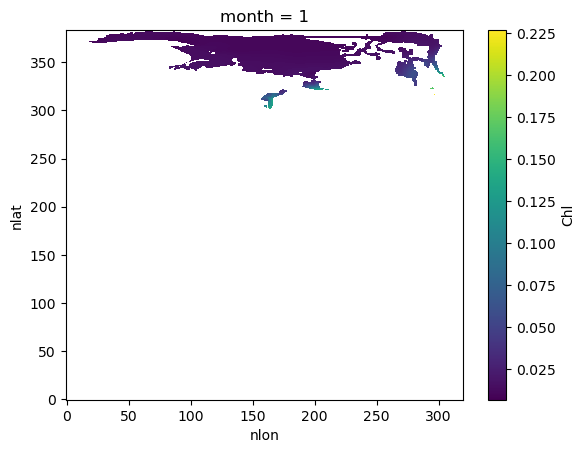

In [14]:
ice_ex_model.plot()

In [15]:
b = 'NH_ICE'

biome_num=biome_num_dict[b]

mon = mons[0]

ice_ex_obs = ds_clim_obs.Chl.isel(month=mon).where(ds_biome_obs.biome == biome_num) #.mean(dim=('nlon','nlat'))

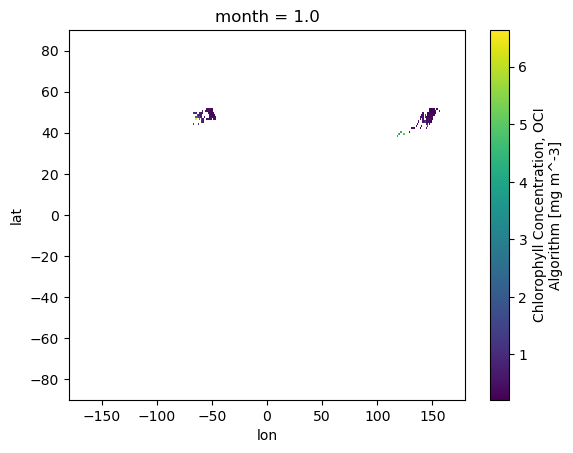

In [16]:
ice_ex_obs.plot()

/glade/u/apps/opt/miniforge/envs/npl-2026a/lib/python3.13/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)


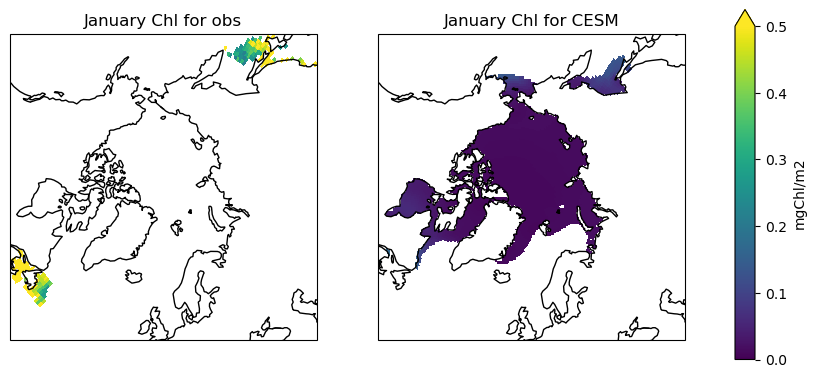

In [26]:
###### 
fig = plt.figure(figsize=(10,5))

cmap = plt.get_cmap('viridis').copy()
cmap.set_bad(color='white')  

ax = fig.add_subplot(1,2,1, projection=ccrs.NorthPolarStereo())
ax.set_extent([-180, 180, 50, 90], ccrs.PlateCarree())
ax.set_title('January Chl for obs', fontsize=12)
pc=ax.pcolormesh(ice_ex_obs.lon, ice_ex_obs.lat, ice_ex_obs, cmap=cmap,
                 vmin=0,vmax=0.5,
                 transform=ccrs.PlateCarree())
ax.coastlines('110m',linewidth=1)

ax = fig.add_subplot(1,2,2, projection=ccrs.NorthPolarStereo())
ax.set_extent([-180, 180, 50, 90], ccrs.PlateCarree())
ax.set_title('January Chl for CESM', fontsize=12)
pc=ax.pcolormesh(lons, lats, ice_ex_model, cmap=cmap,
                 vmin=0,vmax=0.5,
                 transform=ccrs.PlateCarree())
ax.coastlines('110m',linewidth=1)


fig.subplots_adjust(right=0.8)
cbar_ax = fig.add_axes([0.85, 0.15, 0.02, 0.7])
cbar1 = fig.colorbar(pc, cax=cbar_ax,extend='max',label='mgChl/m2');

In [18]:
ice_ex_model

<xarray.DataArray 'Chl' (nlat: 384, nlon: 320)> Size: 492kB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]],
      shape=(384, 320), dtype=float32)
Coordinates:
    TLAT     (nlat, nlon) float64 983kB -79.22 -79.22 -79.22 ... nan nan nan
    TLONG    (nlat, nlon) float64 983kB 320.6 321.7 322.8 323.9 ... nan nan nan
    month    int64 8B 1
Dimensions without coordinates: nlat, nlon

In [53]:
%%time

chl_means_biome_model_dict = {}
sst_means_biome_model_dict = {}
chl_std_biome_model_dict = {}
sst_std_biome_model_dict = {}

chl_means_biome_obs_dict = {}
sst_means_biome_obs_dict = {}
chl_std_biome_obs_dict = {}
sst_std_biome_obs_dict = {}

i = 0

for b in biome_names:

    biome_num = biome_num_dict[b]
    print(b)
    
    chl_mean_vals = np.zeros((12))
    chl_std_vals = np.zeros((12))
    sst_mean_vals = np.zeros((12))
    sst_std_vals = np.zeros((12))
    
    i=0
    for mon in mons:

        sst_mean_vals[i] = ds_clim_model.TEMP.isel(month=mon).where(ds_biome_model.biome == biome_num).mean(dim=('nlon','nlat')).values
        sst_std_vals[i] = ds_clim_model.TEMP.isel(month=mon).where(ds_biome_model.biome == biome_num).std(dim=('nlon','nlat')).values
        chl_mean_vals[i] = ds_clim_model.Chl.isel(month=mon).where(ds_biome_model.biome == biome_num).mean(dim=('nlon','nlat')).values
        chl_std_vals[i] = ds_clim_model.Chl.isel(month=mon).where(ds_biome_model.biome == biome_num).std(dim=('nlon','nlat')).values
        i = i + 1
        

    chl_means_biome_model_dict[b] = chl_mean_vals
    sst_means_biome_model_dict[b] = sst_mean_vals
    chl_std_biome_model_dict[b] = chl_std_vals
    sst_std_biome_model_dict[b] = sst_std_vals

    print('did model')

    ### Now do OBS ###############################
    
    chl_mean_vals = np.zeros((12))
    chl_std_vals = np.zeros((12))
    sst_mean_vals = np.zeros((12))
    sst_std_vals = np.zeros((12))
    
    i=0
    for mon in mons:

        sst_mean_vals[i] = ds_clim_obs.SST.isel(month=mon).where(ds_biome_obs.biome == biome_num).mean(dim=('lon','lat')).values
        sst_std_vals[i] = ds_clim_obs.SST.isel(month=mon).where(ds_biome_obs.biome == biome_num).std(dim=('lon','lat')).values
        chl_mean_vals[i] = ds_clim_obs.Chl.isel(month=mon).where(ds_biome_obs.biome == biome_num).mean(dim=('lon','lat')).values
        chl_std_vals[i] = ds_clim_obs.Chl.isel(month=mon).where(ds_biome_obs.biome == biome_num).std(dim=('lon','lat')).values

        i = i + 1
        

    chl_means_biome_obs_dict[b] = chl_mean_vals
    sst_means_biome_obs_dict[b] = sst_mean_vals
    chl_std_biome_obs_dict[b] = chl_std_vals
    sst_std_biome_obs_dict[b] = sst_std_vals
    print('did obs')
    
    i = i + 1

NH_ICE
did model
did obs
NPac_SPSS
did model
did obs
NAtl_SPSS
did model
did obs
NH_STSS
did model
did obs
NH_STPS
did model
did obs
IND_STPS
did model
did obs
WPac_EQ
did model
did obs
EPac_EQ
did model
did obs
Atl_EQ
did model
did obs
SH_ICE
did model
did obs
SH_SPSS


/glade/u/apps/opt/conda/envs/npl-2024a/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/glade/u/apps/opt/conda/envs/npl-2024a/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/glade/u/apps/opt/conda/envs/npl-2024a/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


did model
did obs
SH_STSS
did model
did obs
SH_STPS
did model
did obs
CPU times: user 2.15 s, sys: 520 ms, total: 2.67 s
Wall time: 2.68 s


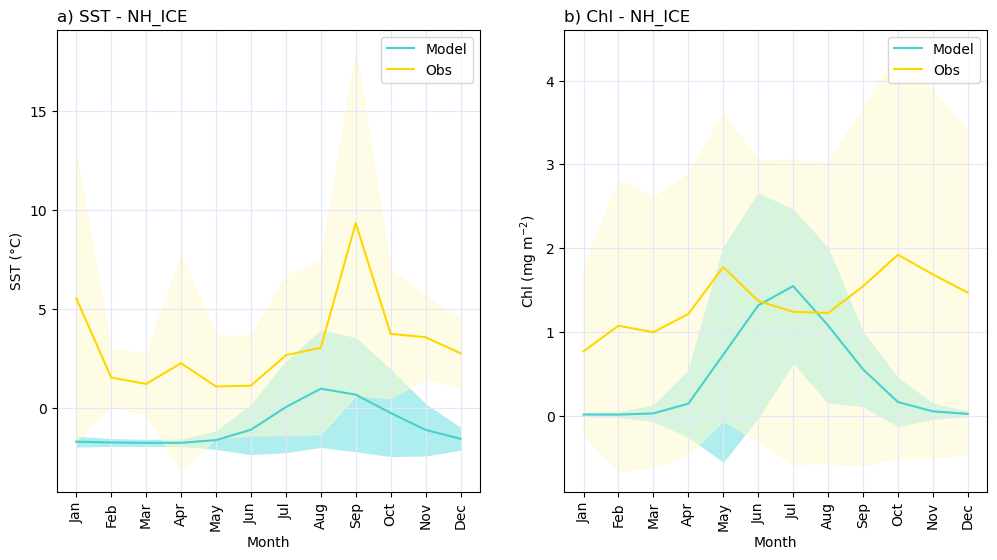

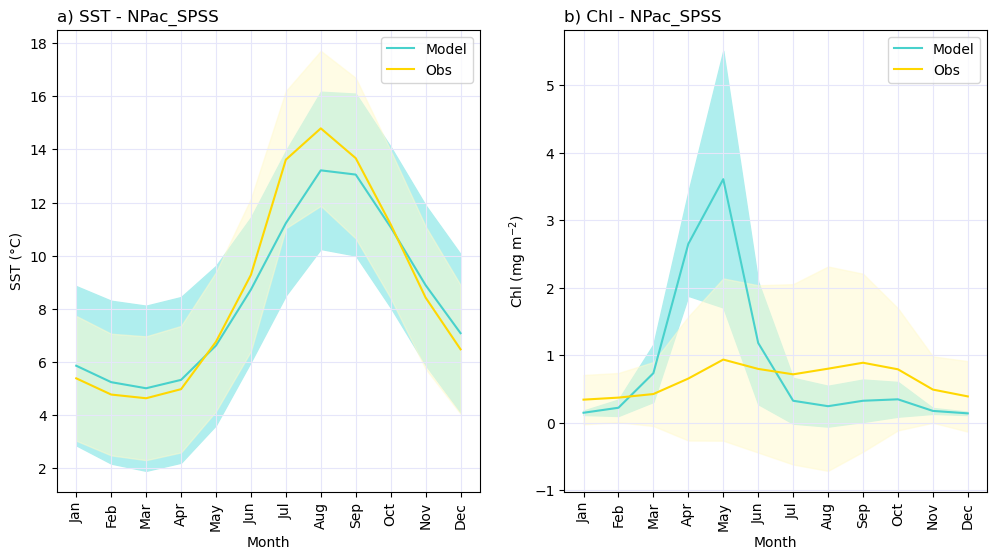

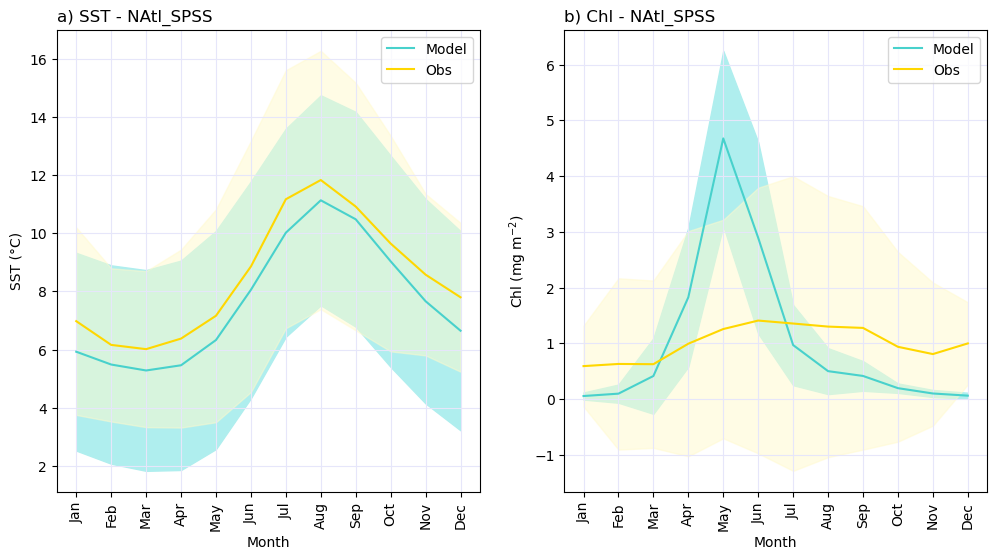

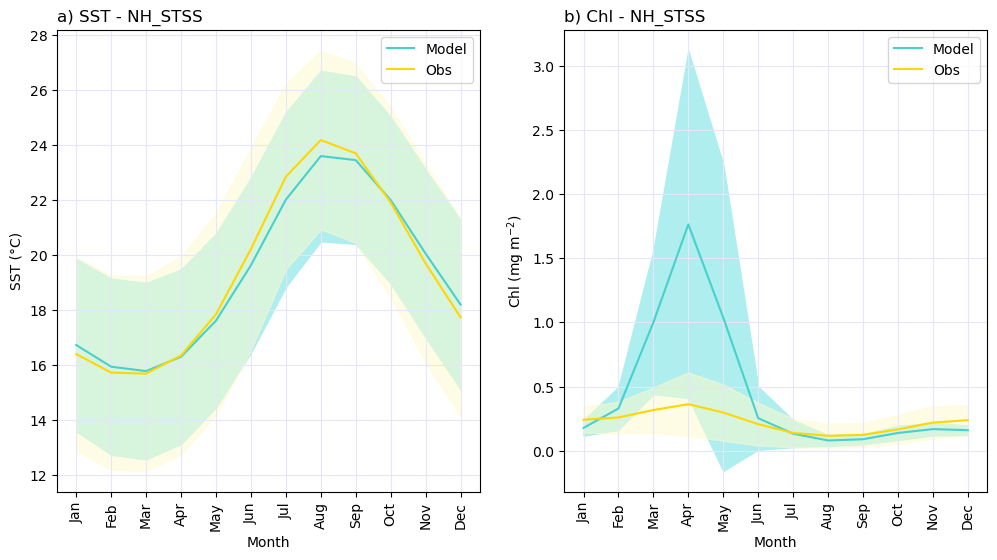

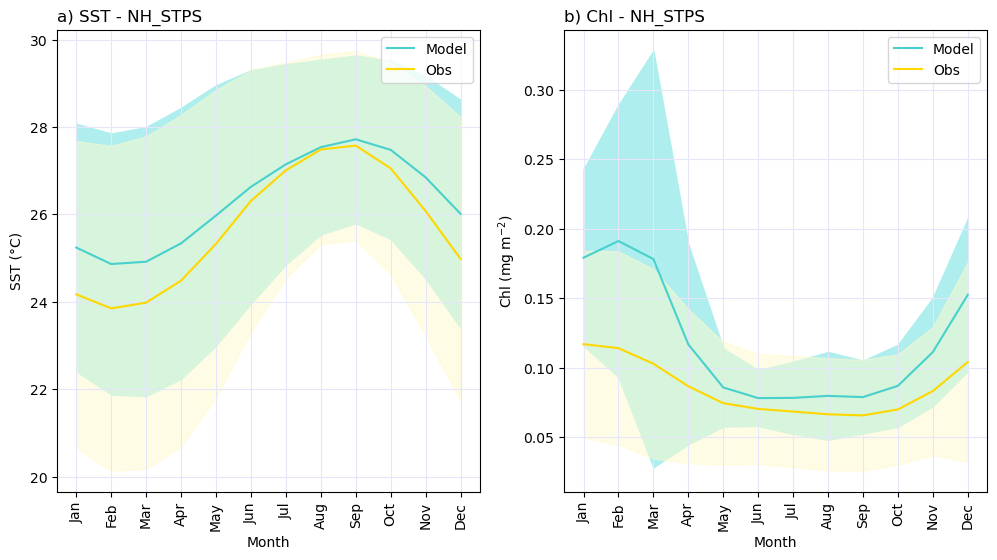

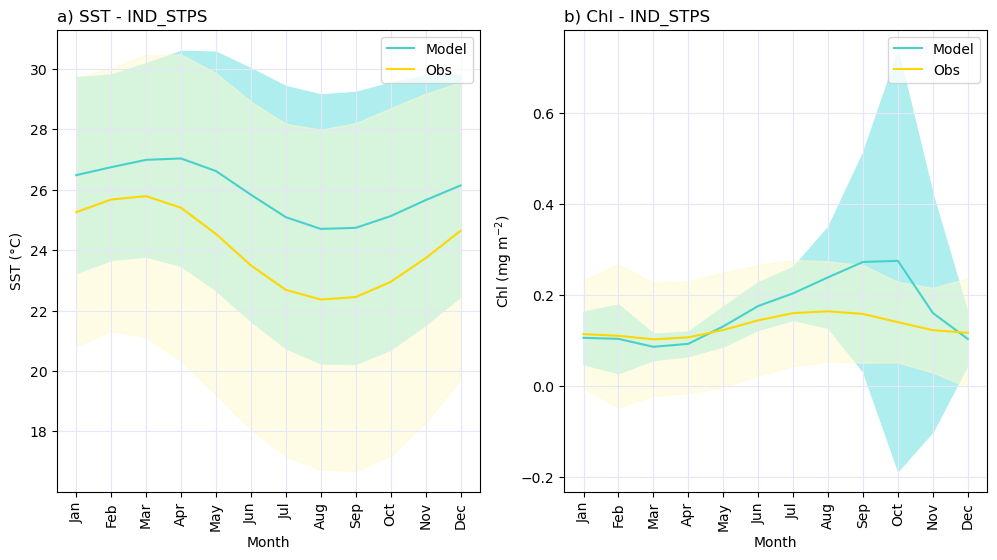

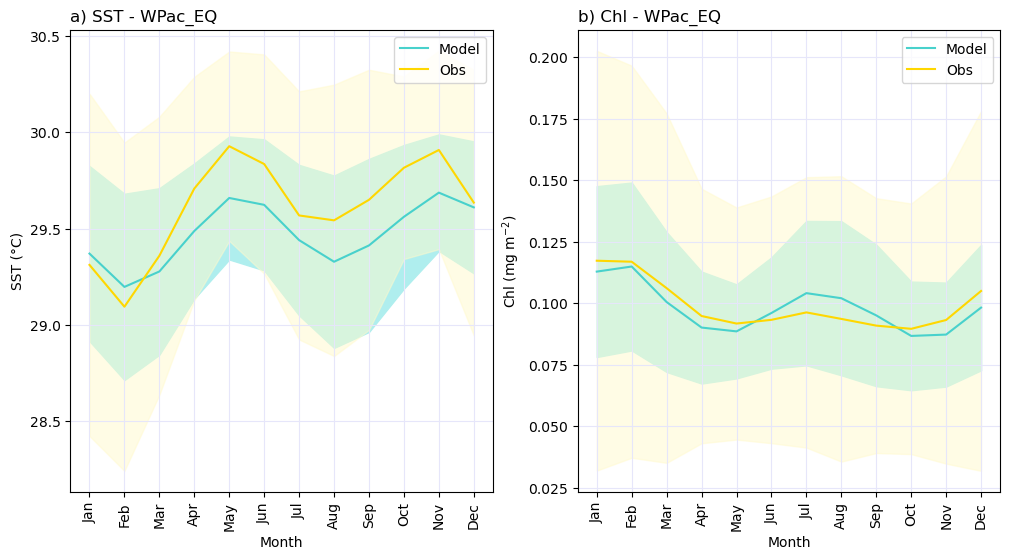

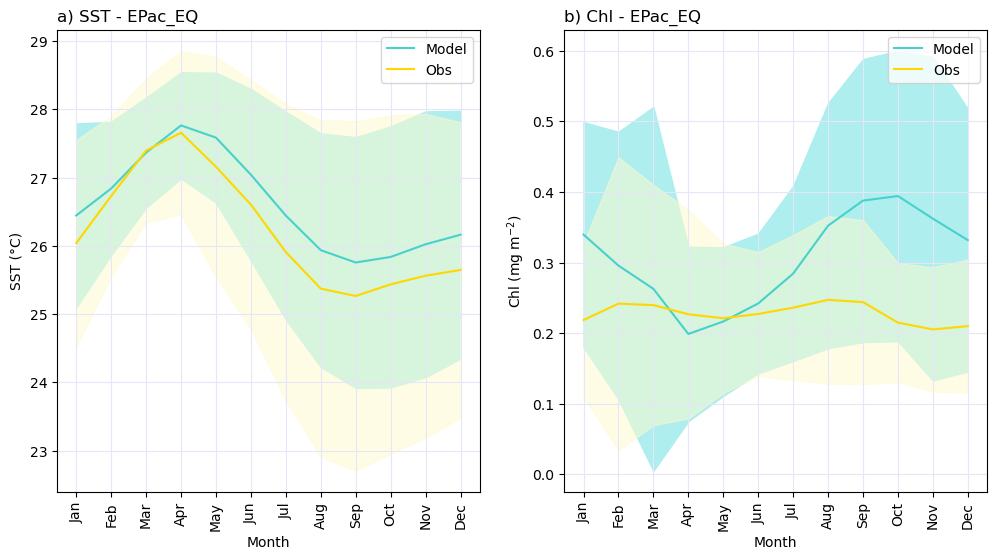

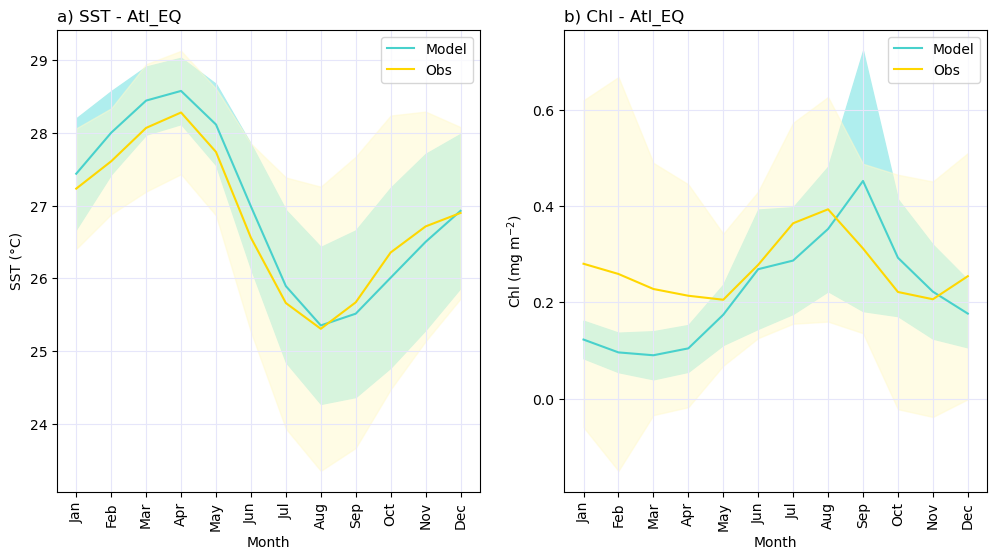

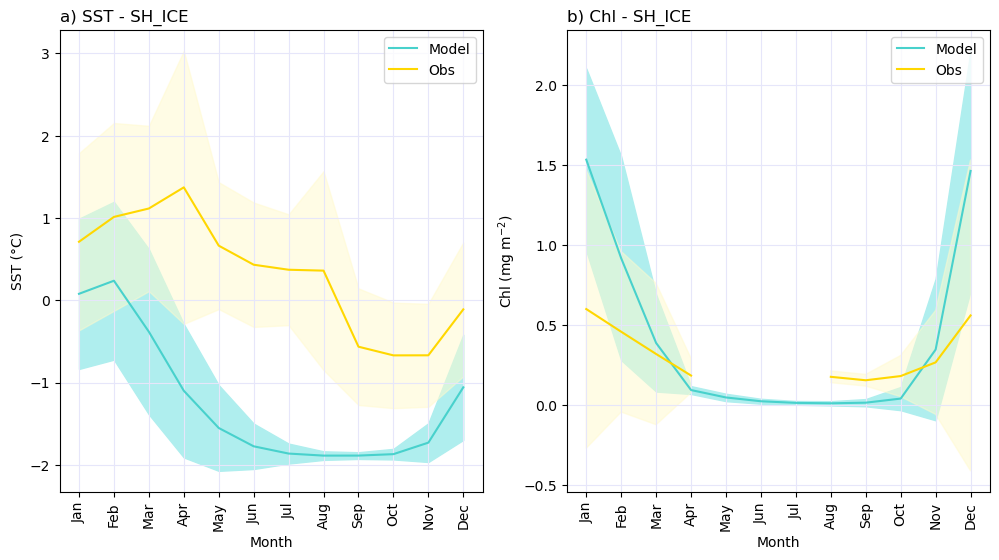

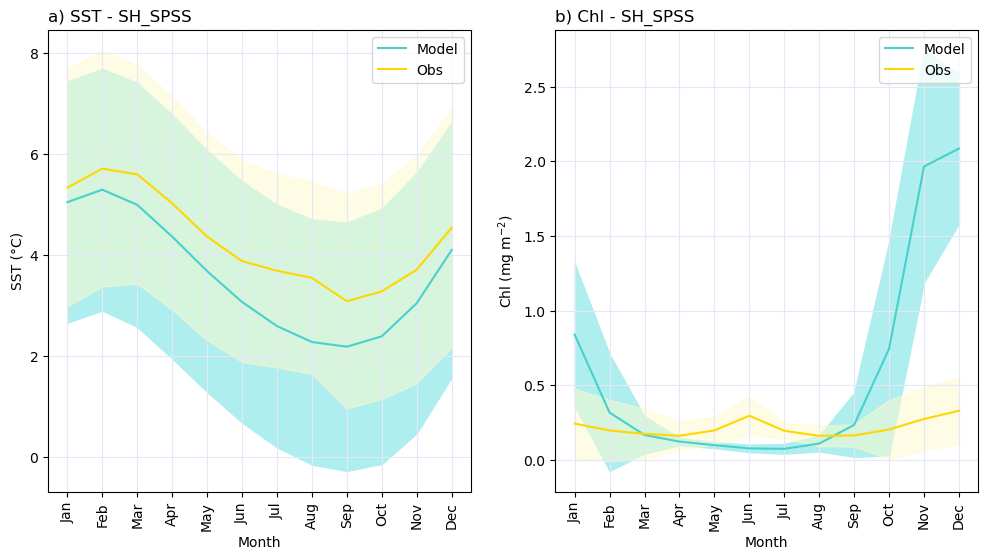

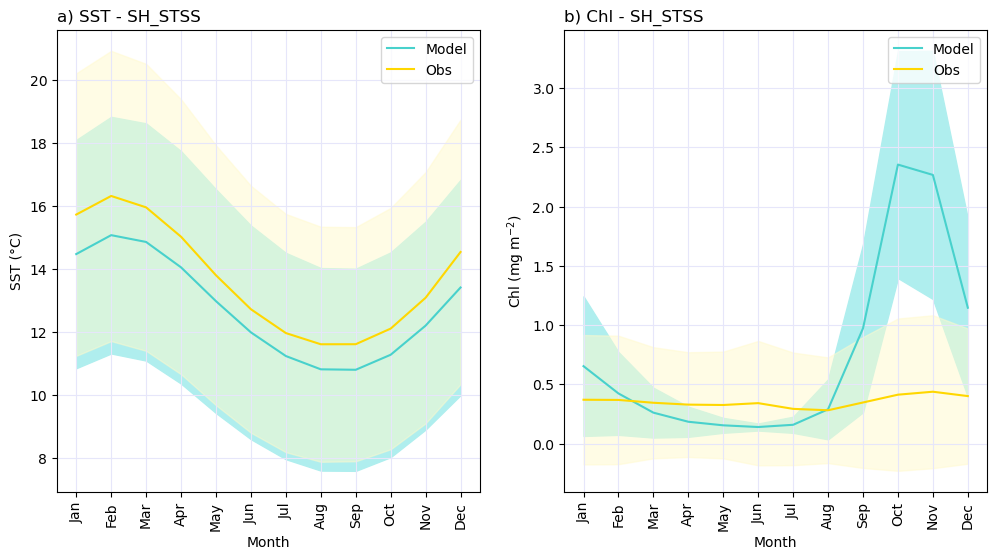

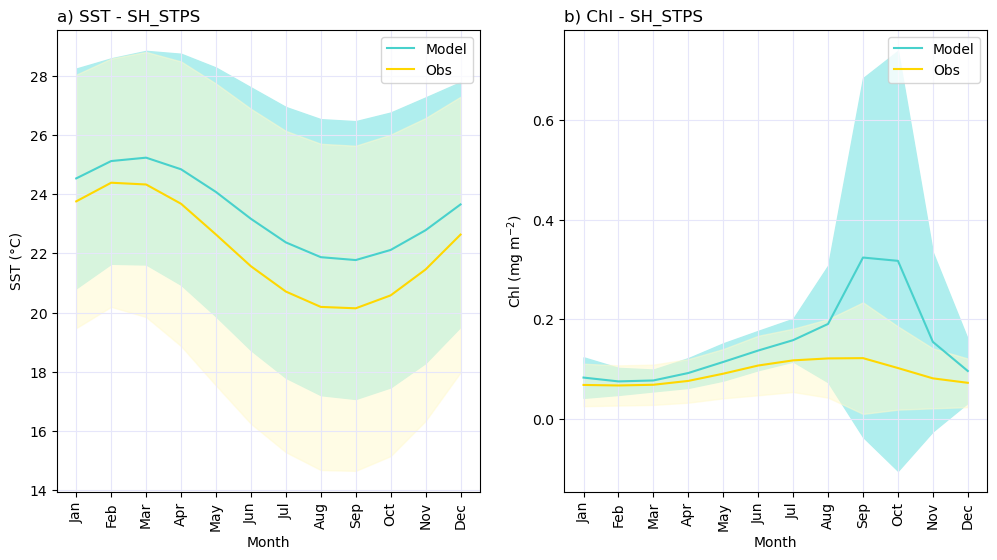

In [70]:
### test with NH_STSS
for biome in biome_names:

    fig = plt.figure(figsize=(12,6))
    
    ####################### SST
    ax = fig.add_subplot(1,2,1)
    ax.set_title('a) SST - ' + biome,fontsize=12,loc='left')
    ax.set_ylabel('SST (°C)')
    ax.set_xlabel('Month')
    ax.xaxis.grid(True, which='major',color='lavender')
    ax.yaxis.grid(True, which='major',color='lavender')
    
    ### plot model
    ax.plot(mons,sst_means_biome_model_dict[biome], 
             color='mediumturquoise', label='Model', lw=1.5)
    ax.fill_between(mons, sst_means_biome_model_dict[biome] - sst_std_biome_model_dict[biome], 
                    sst_means_biome_model_dict[biome] + sst_std_biome_model_dict[biome],color='paleturquoise')
    
    ### plot obs
    ax.plot(mons,sst_means_biome_obs_dict[biome], 
             color='gold', label='Obs', lw=1.5)
    ax.fill_between(mons, sst_means_biome_obs_dict[biome] - sst_std_biome_obs_dict[biome], 
                    sst_means_biome_obs_dict[biome] + sst_std_biome_obs_dict[biome],color='lemonchiffon',alpha=0.5)
    
    plt.xticks(mons, months, rotation='vertical')
    ax.legend()
    
    ####################### Chl
    ax = fig.add_subplot(1,2,2)
    ax.set_title('b) Chl - ' + biome,fontsize=12,loc='left')
    ax.set_ylabel('Chl (mg m$^{-2}$)')
    ax.set_xlabel('Month')
    ax.xaxis.grid(True, which='major',color='lavender')
    ax.yaxis.grid(True, which='major',color='lavender')
    
    ### plot model
    ax.plot(mons,chl_means_biome_model_dict[biome], 
             color='mediumturquoise', label='Model', lw=1.5)
    ax.fill_between(mons, chl_means_biome_model_dict[biome] - chl_std_biome_model_dict[biome], 
                    chl_means_biome_model_dict[biome] + chl_std_biome_model_dict[biome],color='paleturquoise')
    
    ### plot obs
    ax.plot(mons,chl_means_biome_obs_dict[biome], 
             color='gold', label='Obs', lw=1.5)
    ax.fill_between(mons, chl_means_biome_obs_dict[biome] - chl_std_biome_obs_dict[biome], 
                    chl_means_biome_obs_dict[biome] + chl_std_biome_obs_dict[biome],color='lemonchiffon',alpha=0.5)
    
    plt.xticks(mons, months, rotation='vertical')
    ax.legend()
    plt.show()